# Explicabilidad y análisis de errores

Evidencia para [`explainability.md`](../explainability.md) y [`error_insights.md`](../error_insights.md).

Se usa el **modelo final** de `model_pipeline`: regresión lineal (OLS) con 5 variables, entrenada con los 1 000 pedidos (semilla 17).

- **Parte 1 · Explicabilidad:** ¿qué variables mueven el tiempo de entrega y cuánto?
- **Parte 2 · Errores:** ¿cuándo y por qué se equivoca el modelo?

In [ ]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "model_pipeline").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from model_pipeline import config
from model_pipeline.model import ModeloTiempoEntrega
from model_pipeline.preprocessing import cargar_datos, limpiar_tipos

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

df = cargar_datos(config.RUTA_DATOS)
modelo = ModeloTiempoEntrega().fit(df)          # modelo final: todos los datos
print(modelo.formula)

# Parte 1 · Explicabilidad

## 1.1 Coeficientes: 

Cada coeficiente se lee directamente en **minutos**:
- **Variables numéricas:** cuántos minutos cambia la entrega por cada unidad más (1 km, 1 minuto de preparación, 1 año de experiencia), dejando todo lo demás igual.
- **Variables categóricas:** cuántos minutos más o menos tarda una categoría frente a la **categoría de referencia**. La referencia es `High` en tráfico y `Clear` en clima.

El **p-valor** indica si el efecto podría ser casualidad (p < 0,05 = efecto real). Se calcula con errores **robustos HC3**, que siguen siendo válidos aunque el error del modelo crezca en los pedidos largos.
El **intervalo de confianza del 95 %** (IC95) da el rango donde probablemente está el efecto verdadero.

In [16]:
display(modelo.resumen().round(3))

,coef,error_std_HC3,p_valor_HC3,IC95_inf,IC95_sup
Intercept,17.492,1.455,0.000,14.640,20.343
C(Traffic_Level)[T.Low],-11.852,0.978,0.000,-13.769,-9.935
C(Traffic_Level)[T.Medium],-6.186,0.950,0.000,-8.048,-4.323
C(Weather)[T.Foggy],7.338,1.309,0.000,4.773,9.904
C(Weather)[T.Rainy],4.916,0.924,0.000,3.105,6.728
C(Weather)[T.Snowy],9.484,1.184,0.000,7.163,11.805
C(Weather)[T.Windy],1.971,0.854,0.021,0.297,3.645
Distance_km,2.991,0.062,0.000,2.869,3.113
Preparation_Time_min,0.968,0.045,0.000,0.879,1.057
Courier_Experience_yrs,-0.656,0.111,0.000,-0.873,-0.439


- **Distancia (+2,99):** cada km suma unos **3 minutos**, lo que equivale a recorrer ~20 km/h en promedio.
- **Preparación (+0,97):** cada minuto en cocina se traslada **casi 1 a 1** a la entrega. El repartidor no compensa la espera.
- **Experiencia (−0,66):** cada año de experiencia ahorra unos 40 segundos. Un repartidor con 9 años es ~6 min más rápido que uno nuevo.
- **Tráfico:** frente a tráfico alto, el tráfico medio ahorra **6,2 min** y el bajo **11,9 min**.
- **Clima:** frente a cielo despejado, la nieve suma **9,5 min**, la niebla **7,3**, la lluvia **4,9** y el viento **2,0**.
- **Intercepto (17,5):** es el punto de partida de la suma, no un pedido real. Corresponde a 0 km, 0 min de preparación, 0 años de experiencia, cielo despejado y tráfico alto.

Todos los efectos son significativos (p < 0,05) y tienen el signo esperado.

## 1.2 Importancia de cada variable (SHAP)

**SHAP** mide cuánto **mueve cada variable la predicción de un pedido**, comparado con el pedido promedio:
- Para un pedido de 15 km, si el promedio es 10 km, la distancia lo empuja **+15 min** (5 km × 3 min) por encima del promedio. Ese es su valor SHAP.
- La **importancia global** es el promedio de esos empujones en valor absoluto (sin signo) sobre los 1 000 pedidos.

En un modelo lineal, SHAP tiene una fórmula exacta: **coeficiente × (valor del pedido − valor promedio)**. 

In [17]:
X = modelo._preparar(df)
p = modelo.modelo_.params

# Aporte en minutos de cada variable, pedido por pedido
aporte = pd.DataFrame(index=X.index)
for t in modelo.terminos:
    if t.startswith("C("):
        v = t[2:-1]
        aporte[v] = X[v].map(lambda c: p.get(f"{t}[T.{c}]", 0.0))   # categoría de referencia = 0
    else:
        aporte[t] = p[t] * X[t]

shap_lineal = aporte - aporte.mean()        # empujón respecto al pedido promedio

importancia = pd.DataFrame({
    "media_|SHAP|_min": shap_lineal.abs().mean(),
    "rango_P5_P95_min": aporte.quantile(.95) - aporte.quantile(.05),
}).sort_values("media_|SHAP|_min", ascending=False)
importancia["% del total"] = importancia["media_|SHAP|_min"] / importancia["media_|SHAP|_min"].sum() * 100

print(f"Pedido promedio: {p['Intercept'] + aporte.mean().sum():.1f} min")
display(importancia.round(1))

Pedido promedio: 56.7 min


,media_|SHAP|_min,rango_P5_P95_min,% del total
Distance_km,14.8,52.6,50.8
Preparation_Time_min,6.1,21.3,20.8
Traffic_Level,3.6,11.9,12.4
Weather,3.0,9.5,10.4
Courier_Experience_yrs,1.6,5.9,5.6


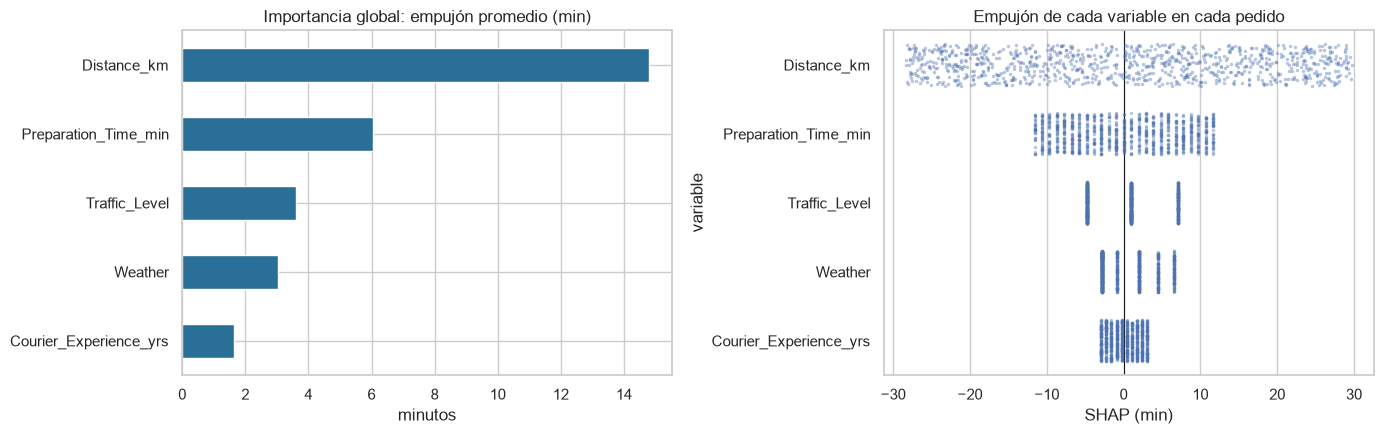

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
importancia["media_|SHAP|_min"][::-1].plot.barh(ax=ax[0], color="#2a6f97")
ax[0].set(title="Importancia global: empujón promedio (min)", xlabel="minutos")

datos_strip = shap_lineal[importancia.index].melt(var_name="variable", value_name="SHAP (min)")
sns.stripplot(data=datos_strip, y="variable", x="SHAP (min)", ax=ax[1], size=2.5, alpha=.4, jitter=.3)
ax[1].axvline(0, color="k", lw=.8)
ax[1].set_title("Empujón de cada variable en cada pedido")
plt.tight_layout(); plt.show()

- **La distancia explica la mitad** (~51 %): en promedio mueve la predicción ±14,8 min respecto al pedido promedio. Entre un pedido cercano y uno lejano, su aporte cambia ~53 min.
- **La preparación es la segunda** (~21 %, ±6,1 min).
- **El tráfico y el clima** pesan ~10–12 % cada uno. Sus efectos por categoría son grandes, pero solo afectan a parte de los pedidos.
- **La experiencia es la que menos mueve** (~6 %, ±1,6 min).
- **Gráfico de la derecha:** cada punto es un pedido. La distancia se extiende de −30 a +30 min, mientras que la experiencia apenas se aleja de 0.

## 1.3 Explicación de un pedido individual

Como el modelo es una suma, **cada predicción se descompone exactamente en minutos por factor**.

Ejemplo: 7,5 km, 15 min de preparación, repartidor de 3 años, lluvia, tráfico alto, de noche, en bicicleta.

In [19]:
pedido = pd.DataFrame([{"Distance_km": 7.5, "Preparation_Time_min": 15, "Courier_Experience_yrs": 3,
                        "Weather": "Rainy", "Traffic_Level": "High", "Time_of_Day": "Evening", "Vehicle_Type": "Bike"}])
base_min, contribs = modelo.contribuciones(pedido)
tabla = pd.DataFrame(contribs)
print(f"Base (intercepto) = {base_min} min")
display(tabla)
print(f"Base + aportes = {base_min + tabla['minutos'].sum():.2f} min")
display(modelo.predict(pedido))

Base (intercepto) = 17.49 min


,variable,valor,minutos
0,Distance_km,7.5,22.43
1,Preparation_Time_min,15,14.52
2,Traffic_Level,High,0.00
3,Weather,Rainy,4.92
4,Courier_Experience_yrs,3,-1.97


Base + aportes = 57.39 min


,prediccion_min,limite_inf,limite_sup,alerta
0,57.387604,43.862538,72.335442,


Se parte de 17,5 min y se suma cada aporte:
- distancia: 7,5 km × 2,99 = **+22,4** min;
- preparación: 15 min × 0,97 = **+14,5** min;
- tráfico alto: **0**, porque es la referencia;
- lluvia: **+4,9** min;
- experiencia: 3 años × −0,66 = **−2,0** min.

El total es **57,4 min**, con un intervalo del 90 % entre 43,9 y 72,3 min. 

# Parte 2 · Análisis de errores

**Error = tiempo real − tiempo predicho.**
- **Error positivo:** el pedido tardó **más** de lo predicho. El modelo **subestimó**: es el caso que le duele al cliente.
- **Error negativo:** el pedido llegó **antes** de lo predicho. El modelo **sobreestimó**.

In [20]:
crudo = limpiar_tipos(df)
d = pd.concat([crudo, modelo.oof_[["pred_oof", "error"]]], axis=1)
d["abs"] = d["error"].abs()
d["con_faltante"] = crudo[modelo.variables_usadas].isna().any(axis=1)
e = d["error"]

## 2.1 Sesgo medio: ¿el modelo tiende a quedarse corto o a pasarse?

El **sesgo medio** es el promedio de los errores **con signo**. Responde: *"en promedio, ¿el modelo promete menos o más tiempo del real?"*
- **Sesgo ≈ 0:** los errores hacia arriba y hacia abajo se compensan. El modelo no está inclinado hacia ningún lado.
- **Sesgo positivo:** se queda corto sistemáticamente (los pedidos tardan más de lo prometido).
- **Sesgo negativo:** se pasa sistemáticamente (promete más tiempo del necesario).


In [21]:
print(f"Sesgo medio:          {e.mean():+.2f} min")
print(f"Mediana del error:    {e.median():+.2f} min")
print(f"Error absoluto (MAE): {d['abs'].mean():.2f} min\n")

for k in [5, 10, 20]:
    print(f"Pedidos con error de ±{k:2d} min o menos: {(d['abs'] <= k).mean():.0%}")

print(f"\nSubestima (tardó más): {(e > 0).mean():.0%} de los pedidos, en promedio por {e[e > 0].mean():.1f} min")
print(f"Sobreestima (llegó antes): {(e < 0).mean():.0%} de los pedidos, en promedio por {-e[e < 0].mean():.1f} min")

grandes = d["abs"] > 20
print(f"\nErrores de más de 20 min: {grandes.sum()} pedidos; {(e[grandes] > 0).mean():.0%} son subestimaciones")

Sesgo medio:          +0.02 min
Mediana del error:    -1.25 min
Error absoluto (MAE): 6.55 min

Pedidos con error de ± 5 min o menos: 56%
Pedidos con error de ±10 min o menos: 82%
Pedidos con error de ±20 min o menos: 97%

Subestima (tardó más): 41% de los pedidos, en promedio por 8.0 min
Sobreestima (llegó antes): 59% de los pedidos, en promedio por 5.6 min

Errores de más de 20 min: 33 pedidos; 91% son subestimaciones


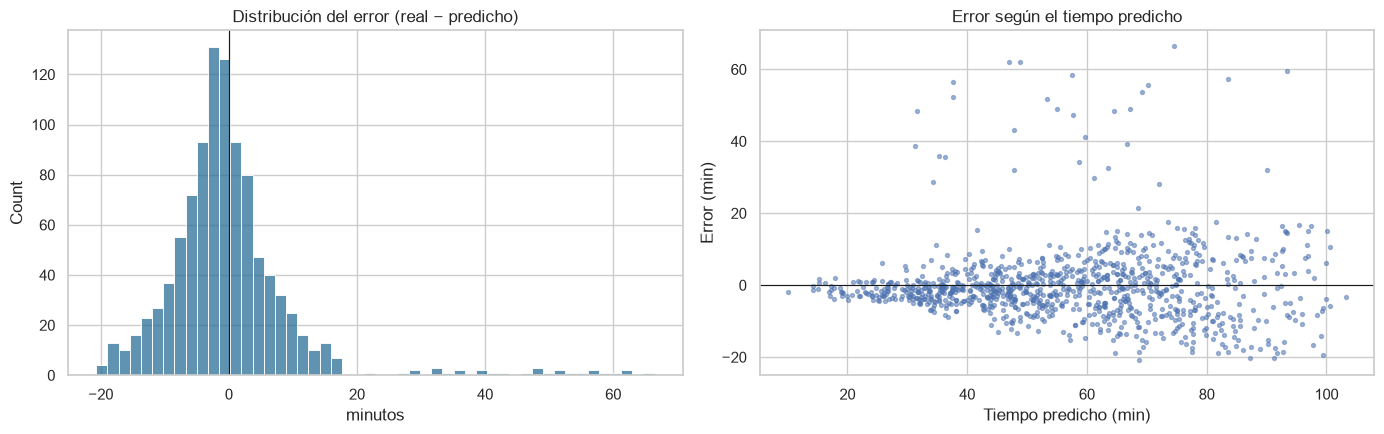

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(e, bins=50, ax=ax[0], color="#2a6f97")
ax[0].axvline(0, color="k", lw=.8)
ax[0].set(title="Distribución del error (real − predicho)", xlabel="minutos")

ax[1].scatter(d["pred_oof"], e, s=8, alpha=.5)
ax[1].axhline(0, color="k", lw=.8)
ax[1].set(xlabel="Tiempo predicho (min)", ylabel="Error (min)", title="Error según el tiempo predicho")
plt.tight_layout(); plt.show()

## 2.2 Error por segmento: ¿en qué pedidos se equivoca más?

Se agrupan los pedidos por cada característica y se calcula, para cada grupo:
- **n:** número de pedidos del grupo.
- **MAE:** cuánto se equivoca en promedio, sin importar el signo (el **tamaño** del error).
- **sesgo:** el promedio con signo (la **dirección** del error, como en 2.1).
- **P90_abs:** el error que **no supera** el 90 % de los pedidos del grupo. Muestra los casos malos, no solo el promedio.

Un buen modelo puede tener MAE distinto entre grupos (algunos pedidos son más difíciles), pero debería tener **sesgo cercano a 0 en todos**. Si un grupo tuviera sesgo grande, el modelo estaría fallando sistemáticamente con ese tipo de pedido.

In [23]:
def por_segmento(col):
    return d.groupby(col, observed=True).agg(
        n=("error", "size"), MAE=("abs", "mean"), sesgo=("error", "mean"),
        P90_abs=("abs", lambda x: x.quantile(.9))).round(1)

d["distancia_km"] = pd.cut(d["Distance_km"], [0, 5, 10, 15, 20])
d["tiempo_predicho"] = pd.qcut(d["pred_oof"], 4, precision=0)
d["preparacion_min"] = pd.cut(d["Preparation_Time_min"], [4, 10, 17, 23, 29])
d["experiencia_anos"] = pd.cut(d["Courier_Experience_yrs"], [-1, 2, 5, 9])

for col in ["distancia_km", "tiempo_predicho", "preparacion_min", "experiencia_anos",
            "Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type", "con_faltante"]:
    print(f"\n=== {col} ===")
    display(por_segmento(col))


=== distancia_km ===


,n,MAE,sesgo,P90_abs
distancia_km,,,,
"(0, 5]",248,3.4,-0.2,5.0
"(5, 10]",241,5.6,0.3,8.8
"(10, 15]",260,6.7,0.4,12.7
"(15, 20]",251,10.3,-0.5,17.3



=== tiempo_predicho ===


,n,MAE,sesgo,P90_abs
tiempo_predicho,,,,
"(9.0, 42.0]",250,3.8,-0.0,5.6
"(42.0, 56.0]",250,5.2,-0.2,8.9
"(56.0, 71.0]",250,7.9,1.2,14.2
"(71.0, 103.0]",250,9.3,-0.9,16.5



=== preparacion_min ===


,n,MAE,sesgo,P90_abs
preparacion_min,,,,
"(4, 10]",246,7.0,-0.2,13.3
"(10, 17]",289,6.5,0.1,13.5
"(17, 23]",221,6.2,0.3,11.5
"(23, 29]",244,6.5,-0.2,13.9


... (8 outputs left out)


=== Vehicle_Type ===


,n,MAE,sesgo,P90_abs
Vehicle_Type,,,,
Bike,503,6.5,0.2,14.1
Car,195,7.0,0.6,14.0
Scooter,302,6.3,-0.6,12.6



=== con_faltante ===


,n,MAE,sesgo,P90_abs
con_faltante,,,,
False,911,6.5,-0.2,13.4
True,89,7.3,2.6,14.3


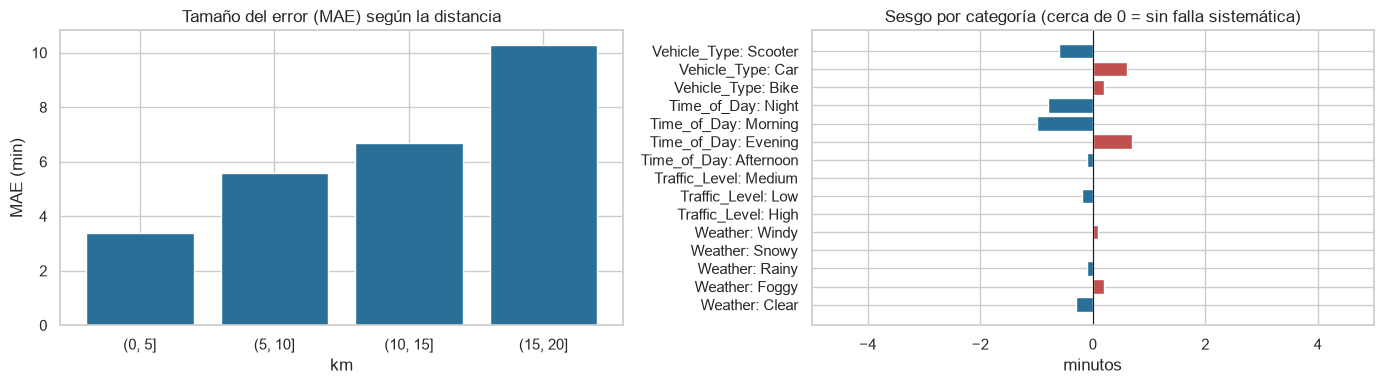

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
seg = por_segmento("distancia_km")
ax[0].bar(seg.index.astype(str), seg["MAE"], color="#2a6f97")
ax[0].set(title="Tamaño del error (MAE) según la distancia", xlabel="km", ylabel="MAE (min)")

seg_c = pd.concat([por_segmento(c)["sesgo"].rename(lambda x: f"{c}: {x}")
                   for c in ["Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type"]])
ax[1].barh(seg_c.index, seg_c.values, color=np.where(seg_c > 0, "#c0504d", "#2a6f97"))
ax[1].axvline(0, color="k", lw=.8); ax[1].set_xlim(-5, 5)
ax[1].set(title="Sesgo por categoría (cerca de 0 = sin falla sistemática)", xlabel="minutos")
plt.tight_layout(); plt.show()

- **La distancia es lo que más cambia el tamaño del error.** El MAE pasa de **3,4 min** en pedidos de hasta 5 km a **10,3 min** en los de 15 a 20 km, unas 3 veces más. En un trayecto largo hay más tramo donde puede pasar algo. El sesgo, en cambio, sigue cerca de 0 en todas las distancias: el modelo no subestima sistemáticamente los pedidos largos, solo es menos preciso con ellos.
- **La preparación y la experiencia no cambian el error:** 
- **Clima:** la niebla (7,8) y la lluvia (7,3) tienen algo más de error que el cielo despejado (6,1). Su efecto medio está bien estimado (sesgo ≈ 0), pero agregan variabilidad: no todos los días de lluvia afectan igual.
- **Tráfico, franja horaria y vehículo:** sesgo de 1 min o menos en todas las categorías. La franja y el vehículo no están en el modelo, y aun así no dejan error sistemático. Esto confirma que excluirlos fue correcto.
- **Pedidos con algún dato faltante:** se subestiman en +2,6 min en promedio, frente a −0,2 sin faltantes. Son solo 89 pedidos, pero conviene vigilarlo. Por eso la API marca en `alerta` cada pedido con datos imputados.

## 2.3 Los peores errores: ¿qué tienen en común?

Se listan los 15 pedidos donde el modelo más se equivocó. Después se compara el grupo con **error de más de 20 min** contra el resto, variable por variable, para ver si tienen algún perfil distinto:
- numéricas con **Mann-Whitney**: ¿la distancia, la preparación o la experiencia de este grupo son distintas?
- categóricas con **Chi-cuadrado**: ¿el clima, el tráfico, la franja o el vehículo se reparten distinto?

In [25]:
cols = ["Order_ID", *config.FEATURES, config.TARGET, "pred_oof", "error"]
display(d.sort_values("abs", ascending=False)[cols].head(15).round(1))

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Delivery_Time_min,pred_oof,error
452,394,15.6,20.0,4.0,Rainy,Low,NaN,Bike,141,74.5,66.5
73,742,6.4,16.0,1.0,Snowy,Low,Evening,Bike,111,48.8,62.2
343,126,8.8,12.0,3.0,NaN,Medium,Evening,Scooter,109,47.0,62.0
379,814,18.5,29.0,1.0,Clear,NaN,NaN,Scooter,153,93.4,59.6
140,45,5.6,18.0,1.0,Foggy,High,Evening,Bike,116,57.5,58.5
127,446,19.0,25.0,4.0,Clear,Low,Evening,Car,141,83.6,57.4
877,813,2.9,24.0,8.0,Clear,Medium,Morning,Bike,94,37.6,56.4
784,385,14.8,19.0,4.0,Rainy,Low,Morning,Car,126,70.2,55.8
29,948,18.0,10.0,7.0,Clear,Medium,Evening,Scooter,123,69.2,53.8
859,773,3.0,9.0,5.0,Foggy,High,Afternoon,Bike,90,37.6,52.4


In [26]:
print(f"Errores de más de 20 min ({grandes.sum()} pedidos) frente al resto ({(~grandes).sum()} pedidos):\n")
for c in config.NUMERICAS:
    pv = stats.mannwhitneyu(d.loc[grandes, c].dropna(), d.loc[~grandes, c].dropna()).pvalue
    print(f"  {c:24s} promedio {d.loc[grandes, c].mean():5.1f} vs {d.loc[~grandes, c].mean():5.1f}   p = {pv:.2f}")
for c in config.CATEGORICAS:
    pv = stats.chi2_contingency(pd.crosstab(grandes, d[c]))[1]
    print(f"  {c:24s} p = {pv:.2f}")

atipicos = d[config.TARGET] > 116
print(f"\nAtípicos del tiempo de entrega (> 116 min, ver EDA): {atipicos.sum()} pedidos, "
      f"error promedio {d.loc[atipicos, 'error'].mean():+.1f} min")

Errores de más de 20 min (33 pedidos) frente al resto (967 pedidos):

  Distance_km              promedio  11.1 vs  10.0   p = 0.27
  Preparation_Time_min     promedio  15.6 vs  17.0   p = 0.26
  Courier_Experience_yrs   promedio   3.9 vs   4.6   p = 0.20
  Weather                  p = 0.08
  Traffic_Level            p = 0.52
  Time_of_Day              p = 0.17
  Vehicle_Type             p = 0.52

Atípicos del tiempo de entrega (> 116 min, ver EDA): 6 pedidos, error promedio +54.2 min


- **Los 15 peores son todos subestimaciones,** de +48 a +66 min. El modelo nunca se equivoca tanto "por exceso".
- **Ninguna variable distingue a los pedidos con errores grandes** (todos los p > 0,05). No son más lejanos, ni con peor clima, ni con repartidores nuevos. Se parecen al resto.
- **5 de los 15 peores son atípicos del EDA** (pedidos de más de 116 min). Se conservaron porque son entregas reales, y el modelo los subestima en ~54 min.

**Conclusión:** los errores grandes no se deben a que el modelo esté mal planteado, sino a **retrasos que no quedan registrados en los datos**.